# 14 · Robustness and fundamental limitations

A controller designed on a model must work on the plant, which differs from the model. This notebook measures
robustness through the gang of four (S, T, PS, CS), the sensitivity peak M_s and the disk margin; shows that
sensitivity cannot be reduced everywhere (Bode's integral, the waterbed effect) and how unstable poles make it
worse; derives the bandwidth limits imposed by right-half-plane zeros, unstable poles and delays; and applies
the small-gain theorem to multiplicative model uncertainty. These limits do not depend on the controller: they
say what no controller can do.

**What you will learn**
- read the gang of four and the sensitivity peak
- state Bode's sensitivity integral and its consequences
- quantify the bandwidth limits of RHP zeros, unstable poles and delays
- apply the small-gain theorem to multiplicative uncertainty

**Before you start:** notebooks 02, 05 and 07  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, robust as rb, frequency as fr, design as dg, response as rs, polynomials as pl, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The gang of four

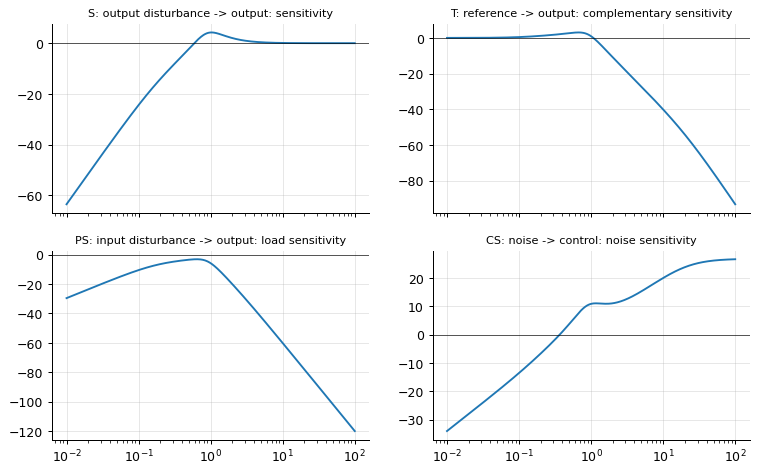

Ms = 1.627 at w = 1.03 rad/s, Mt = 1.422; Ms alone guarantees a gain margin of at least 2.59 and a phase margin of at least 35.8 deg
actual margins: 22.11 and 42.0 deg; disk margin alpha = 0.373


In [2]:
P = sy.tf([1.0], [1.0, 3.0, 2.0, 0.0])
C = dg.pid(2.0, 0.3, 1.0)
g4 = rb.gang_of_four(P, C)
w = np.logspace(-2, 2, 500)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, name, note in zip(axes.ravel(), ("S", "T", "PS", "CS"), ("output disturbance -> output: sensitivity", "reference -> output: complementary sensitivity", "input disturbance -> output: load sensitivity", "noise -> control: noise sensitivity")):
    ax.semilogx(w, 20 * np.log10(np.abs(fr.freqresp(g4[name], w)))); ax.set_title(f"{name}: {note}", fontsize=9); ax.axhline(0, color="k", lw=0.5)
plt.show()
pk = rb.sensitivity_peak(g4["L"])
print(f"Ms = {pk['Ms']:.3f} at w = {pk['w_Ms']:.2f} rad/s, Mt = {pk['Mt']:.3f}; Ms alone guarantees a gain margin of at least {pk['gm_lower_bound']:.2f} and a phase margin of at least {pk['pm_lower_bound_deg']:.1f} deg")
print(f"actual margins: {fr.margins(g4['L'])['gain_margin']:.2f} and {fr.margins(g4['L'])['phase_margin']:.1f} deg; disk margin alpha = {rb.disk_margin(g4['L'])['alpha']:.3f}")

Four transfer functions describe a loop completely: S for disturbances at the output and for how much the
loop reduces model errors (|S| < 1 is where feedback helps), T for reference tracking and for how
measurement noise reaches the output, PS for input disturbances, CS for how much noise the actuator sees.
S + T = 1 at every frequency, so both cannot be small at once: the loop chooses, by frequency. The sensitivity
peak M_s is the most useful single robustness number - the inverse of the Nyquist curve's closest approach to
−1 - and it bounds both classical margins; the disk margin generalises it to simultaneous gain and phase
changes.

## Bode's sensitivity integral: the waterbed

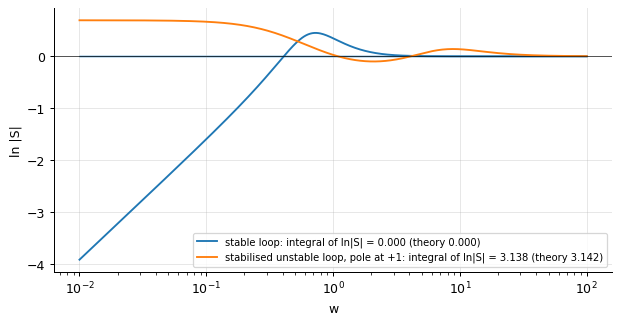

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, L in (("stable loop", sy.tf([1.0], [1.0, 3.0, 2.0, 0.0])), ("stabilised unstable loop, pole at +1", sy.tf([30.0, 60.0], pl.from_roots([1, -5, -8])))):
    bi = rb.bode_sensitivity_integral(L)
    S = 1 / (1 + fr.freqresp(L, w))
    ax.semilogx(w, np.log(np.abs(S)), label=f"{name}: integral of ln|S| = {bi['integral']:.3f} (theory {bi['theory']:.3f})")
ax.axhline(0, color="k", lw=0.5); ax.fill_between(w, 0, 0, color="C0"); ax.legend(fontsize=8); ax.set_xlabel("w"); ax.set_ylabel("ln |S|"); plt.show()

∫₀^∞ ln|S(jω)| dω = π Σ Re(p_k) over the unstable open-loop poles, for loops of relative degree at least two:
the area below zero (where feedback helps) equals the area above (where it hurts) for a stable loop, and the
balance tips against the designer by π per unit of unstable pole. Push |S| down at low frequency and it pops up
elsewhere - the waterbed. The only escapes are a loop with relative degree one (an infinite bandwidth, which
no actuator offers) or accepting the peak where the model is least trusted.

## Right-half-plane zeros, unstable poles, delays

RHP zero at 2.0: the crossover should stay below about 1.0 rad/s


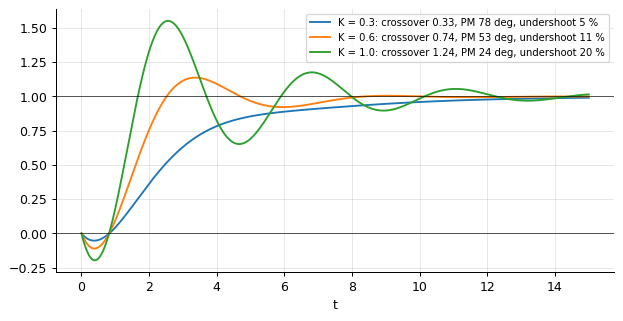


unstable pole at 1 and RHP zero at 4: any stabilising controller has Ms >= |p + z|/|p - z| = 1.667; with the zero at 1.5 it would be 5.0
a delay of 0.2 s limits the crossover to about 5 rad/s


In [4]:
Pz = sy.tf([-1.0, 2.0], [1.0, 2.0, 1.0])                       # (2 - s)/(s + 1)^2: a RHP zero at 2
lim = rb.rhp_limits(Pz)
print(f"RHP zero at {lim['rhp_zeros'][0].real}: the crossover should stay below about {lim['w_c_max_from_zero']:.1f} rad/s")
fig, ax = plt.subplots(figsize=(8, 3.8))
for K in (0.3, 0.6, 1.0):
    C = sy.tf([K, 0.5 * K], [1.0, 0.0])                             # PI with the zero at -0.5
    L = sy.series(C, Pz)
    T = sy.feedback(L)
    t, y = rs.step(T, 15.0)
    m = fr.margins(L)
    ax.plot(t, y, label=f"K = {K}: crossover {m['w_gc']:.2f}, PM {m['phase_margin']:.0f} deg, undershoot {-min(y) * 100:.0f} %")
ax.axhline(0, color="k", lw=0.5); ax.axhline(1, color="k", lw=0.5); ax.legend(fontsize=8); ax.set_xlabel("t"); plt.show()
lim2 = rb.rhp_limits(sy.tf([1.0, -4.0], [1.0, -1.0, 0.0]))
print(f"\nunstable pole at 1 and RHP zero at 4: any stabilising controller has Ms >= |p + z|/|p - z| = {lim2['Ms_lower_bound']:.3f}; with the zero at 1.5 it would be {rb.rhp_limits(sy.tf([1.0, -1.5], [1.0, -1.0, 0.0]))['Ms_lower_bound']:.1f}")
print(f"a delay of 0.2 s limits the crossover to about {rb.rhp_limits(P, delay=0.2)['w_c_max_from_delay']:.0f} rad/s")

A right-half-plane zero at z bounds the achievable bandwidth to roughly z/2: pushing the crossover towards it
costs phase (the zero's phase goes the wrong way) and deepens the inverse response, and a RHP zero close to an
unstable pole makes the plant nearly uncontrollable in practice - M_s ≥ |p + z|/|p − z| grows without limit as
they approach. A delay L bounds the crossover to about 1/L. These are properties of the plant, and the right
response is to change the plant (move the sensor, remove the delay) rather than to fight them with a cleverer
controller.

## Model uncertainty and the small-gain theorem

In [5]:
P = sy.tf([1.0], [1.0, 3.0, 2.0, 0.0])
C = dg.pid(2.0, 0.3, 1.0)
L = sy.series(C, P)
W = sy.tf([0.5, 0.0], [1.0 / 20.0, 1.0])                     # multiplicative uncertainty: 0 at dc, 50 % at 10 rad/s, 1000 % at high frequency
r = rb.multiplicative_robustness(L, W)
print(f"robust stability for P (1 + W Delta), |Delta| <= 1: peak of |W T| = {r['peak_WT']:.3f} at w = {r['w_peak']:.2f} -> {'robustly stable' if r['robustly_stable'] else 'NOT guaranteed'}")
C2 = dg.pid(6.0, 1.0, 3.0)
r2 = rb.multiplicative_robustness(sy.series(C2, P), W)
print(f"a faster controller (3x the gains): peak |W T| = {r2['peak_WT']:.3f} -> {'robustly stable' if r2['robustly_stable'] else 'NOT guaranteed'}; its nominal margins: GM {fr.margins(sy.series(C2, P))['gain_margin']:.2f}, PM {fr.margins(sy.series(C2, P))['phase_margin']:.0f} deg")
sg = rb.small_gain(sy.tf([0.5], [1.0, 1.0]), 1.5)
print(f"\nsmall-gain theorem on M = 0.5/(s + 1) with |Delta| < 1.5: ||M||_inf = {sg['M_inf']:.3f}, product {sg['M_inf'] * 1.5:.3f} < 1 -> stable for every such Delta")

robust stability for P (1 + W Delta), |Delta| <= 1: peak of |W T| = 0.566 at w = 0.91 -> robustly stable
a faster controller (3x the gains): peak |W T| = 1.787 -> NOT guaranteed; its nominal margins: GM 7.35, PM 27 deg

small-gain theorem on M = 0.5/(s + 1) with |Delta| < 1.5: ||M||_inf = 0.500, product 0.750 < 1 -> stable for every such Delta


If the true plant is P(1 + WΔ) with an unknown stable Δ of gain at most one, the loop stays stable for every Δ
exactly when |W T| < 1 at all frequencies: the complementary sensitivity must roll off before the model's
uncertainty grows. The faster controller has good *nominal* margins and still fails the test, because its
bandwidth reaches into the frequencies where the model is 50 % wrong. The small-gain theorem is the general
statement: a loop of two stable systems is stable if the product of their gains is below one - the
foundation of the robust-control methods beyond this course.

## Inside the algorithm: Ms as the closest approach to -1

In [6]:
w_ = np.logspace(-2, 2, 20000)
Lj = fr.freqresp(g4["L"], w_)
print(f"min |1 + L| = {np.min(np.abs(1 + Lj)):.4f} -> Ms = {1 / np.min(np.abs(1 + Lj)):.4f}; library {rb.sensitivity_peak(g4['L'])['Ms']:.4f}")

min |1 + L| = 0.6144 -> Ms = 1.6275; library 1.6275


## Exercises
1. For the levitated ball (unstable pole at 44 rad/s) design a lead controller with crossovers of 50, 100 and 200 rad/s and tabulate Ms, the margins and the peak |CS|. Confirm that the crossover must exceed about 2p for a decent Ms, and read the price in noise amplification.
2. The plant (2 - s)/(s + 1)^2 under a PI controller: compute Ms as a function of the controller gain K and find the gain that minimises it; compare the corresponding crossover with the z/2 rule.
3. **Implement it yourself:** verify Bode's integral numerically for the stabilised unstable loop of the notebook by integrating ln|S| on a fine grid up to 10^5 rad/s, and show that truncating the integral at 100 rad/s misses a visible fraction (the tail decays slowly).